In [ ]:
!unzip "archive (6).zip" -d data
!ls data

Archive:  archive (6).zip
  inflating: data/dataset.csv        
dataset.csv


In [ ]:
CSV_PATH = "dataset.csv"


In [ ]:
CSV_PATH = "data/dataset.csv"


In [ ]:
import re, string
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

In [ ]:
df = pd.read_csv("data/dataset.csv")
print(df.head())
print("Missing values:\n", df.isnull().sum())

                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
Missing values:
 Text        0
language    0
dtype: int64


In [ ]:
TEXT_COL, LABEL_COL = "Text", "language"
df = df.dropna(subset=[TEXT_COL, LABEL_COL]).drop_duplicates()

In [ ]:
def clean(t):
    t = str(t).lower()
    t = re.sub(r"[0-9]+", " ", t)
    t = t.translate(str.maketrans({c: " " for c in string.punctuation}))
    return re.sub(r"\s+", " ", t).strip()

In [ ]:
df[TEXT_COL] = df[TEXT_COL].apply(clean)
df = df[df[TEXT_COL].str.len() > 0]

In [ ]:
df = df.sample(frac=1, random_state=42).groupby(LABEL_COL).head(500).reset_index(drop=True)
print("Subset size:", len(df), "| Languages:", df[LABEL_COL].nunique())

Subset size: 11000 | Languages: 22


In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

y = LabelEncoder().fit_transform(df["language"])
x_train, x_test, y_train, y_test = train_test_split(df["Text"], y, test_size=0.2)

tok = Tokenizer(char_level=True)
tok.fit_on_texts(x_train)

X_train = pad_sequences(tok.texts_to_sequences(x_train), maxlen=100)
X_test = pad_sequences(tok.texts_to_sequences(x_test), maxlen=100)

print(X_train.shape)

(8800, 100)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

vocab_size = len(tok.word_index) + 1
num_classes = 22

model = Sequential([
    Embedding(vocab_size, 32),
    LSTM(64),
    Dense(num_classes, activation="softmax")
])

model.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam", metrics=["accuracy"])

model.build(input_shape=(None, 100))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 32)        │       191,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        24,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 22)             │         1,430 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 217,590 (849.96 KB)

 Trainable params: 217,590 (849.96 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# puthu model
model = Sequential([
    Embedding(vocab_size, 64),
    LSTM(128),
    Dense(22, activation="softmax")
])
model.compile(loss="sparse_categorical_crossentropy",
              optimizer="adam", metrics=["accuracy"])

# training (15 epochs)
model.fit(X_train, y_train, epochs=15, batch_size=64, validation_split=0.1)

# metrics
y_pred = np.argmax(model.predict(X_test), axis=1)
print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, average="weighted", zero_division=0))
print("Recall   :", recall_score(y_test, y_pred, average="weighted", zero_division=0))
print("F1-score :", f1_score(y_test, y_pred, average="weighted", zero_division=0))

Epoch 1/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.3134 - loss: 2.1397 - val_accuracy: 0.4500 - val_loss: 1.5433
Epoch 2/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4894 - loss: 1.4959 - val_accuracy: 0.5784 - val_loss: 1.3229
Epoch 3/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5799 - loss: 1.2689 - val_accuracy: 0.6216 - val_loss: 1.1764
Epoch 4/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6153 - loss: 1.1549 - val_accuracy: 0.6614 - val_loss: 1.0817
Epoch 5/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6612 - loss: 1.0122 - val_accuracy: 0.7136 - val_loss: 0.9386
Epoch 6/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6696 - loss: 0.9745 - val_accuracy: 0.6875 - val_loss: 0.9644
Epoch 7/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6958 - loss: 0.9043 - val_accuracy: 0.7307 - val_loss: 0.8278
Epoch 8/15
124/124 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7457 - loss: 0.7556 - val_accuracy: 0

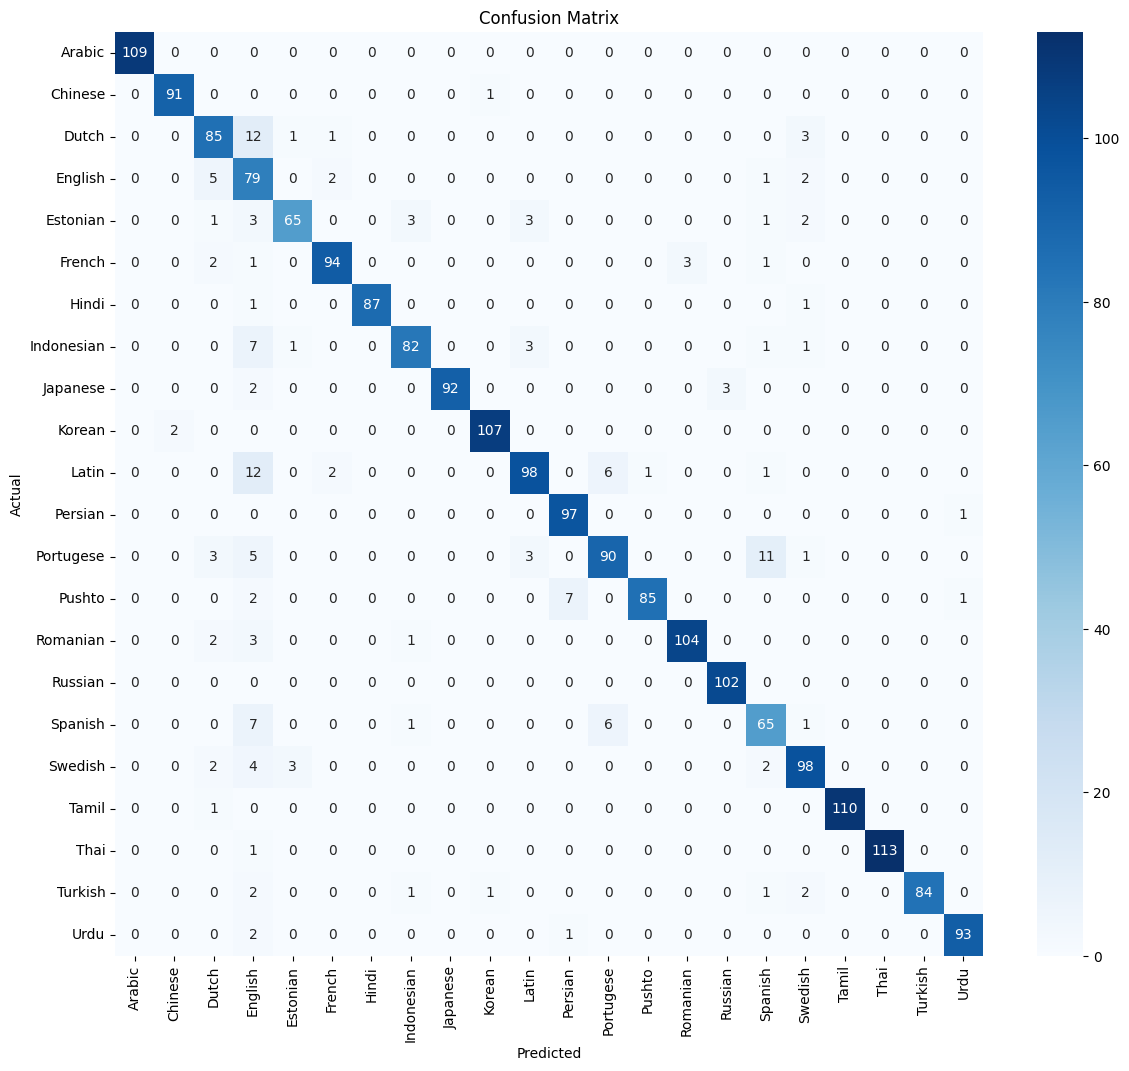

Text     : 近代京都建築を手本に設計され、外壁には輸入英国製煉瓦、屋根部分は緑青銅版、白壁部分はテラコッタ、建物土台部分には御影石が使用されている。また建物正面（東側）と裏
Actual   : Japanese
Predicted: Japanese

Text     : पिछले सालों में भारत में कॉफ़ी का उत्पादन प्रतिशत से अधिक बढ़ गया है। से भारत मे
Actual   : Hindi
Predicted: Hindi

Text     : ஆம் ஆண்டில் நடைபெற்ற பேராக் போரில் பாப்பான் நகரமும் பாதிக்கப்பட்டது பாசிர் சாலாக
Actual   : Tamil
Predicted: Tamil

Text     : 내가 주장하는 가설은 년의 것을 더욱 구체화한 것이다 내가 보기에 우리는 우리에게 친숙한 사람을 다음과 같은 두가지 방법을 모두 사용하여 분별한
Actual   : Korean
Predicted: Korean

Text     : بدأت حركة ما بعد الحداثة بالهندسة المعمارية وذلك استجابةً للميوعة المتصورة والعد
Actual   : Arabic
Predicted: Arabic



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import confusion_matrix

# language names (number -> per)
le = LabelEncoder().fit(df["language"])

# 1. Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# 2. 5 unseen samples (test data, model training-la paakkaadhadhu)
texts = list(x_test)
for i in range(5):
    seq = pad_sequences(tok.texts_to_sequences([texts[i]]), maxlen=100)
    pred = np.argmax(model.predict(seq, verbose=0))
    print("Text     :", texts[i][:80])
    print("Actual   :", le.classes_[y_test[i]])
    print("Predicted:", le.classes_[pred])
    print()